# Petals to the Metal — Flower Classification on Mac M1

## โจทย์
- จำแนกรูปดอกไม้ `104` ชนิด
- วัดผลด้วย `Macro F1-score`
- ไฟล์ submission มีคอลัมน์ `id`, `label`

## วิธีรันบน Mac M1 (GPU ผ่าน Metal)
1. `uv sync` — ติดตั้ง `tensorflow 2.18` + `tensorflow-metal` ตาม `pyproject.toml`
2. วางข้อมูลไว้ที่ `data/tpu-getting-started/` (มีโฟลเดอร์ `tfrecords-jpeg-*`)
3. เลือก kernel ของ `.venv` แล้ว **Run All** — cell เลือก device ควรขึ้น `✅ ใช้ GPU (Metal)`

> **ทำไมไม่ใช้ Neural Engine?** TensorFlow (และ framework อื่น) train บน Neural Engine ไม่ได้ — Apple เปิดให้ใช้ผ่าน Core ML สำหรับ *inference* เท่านั้น การ train บน M1 จึงใช้ **GPU ผ่าน `tensorflow-metal`**
>
> **ทำไมต้อง TF 2.18?** `tensorflow-metal 1.2.0` (ตัวล่าสุด) ใช้กับ TF 2.19+ ไม่ได้ — `import tensorflow` จะพังทันที

ยังรันบน Kaggle TPU ได้เหมือนเดิม: Add Input → *Petals to the Metal* · Accelerator → TPU

## Step 1: Setup — imports, TPU, config, TFRecord files

### Imports

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "1"

import re, glob
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)

TensorFlow: 2.18.1


### Select device: GPU (Metal) → TPU → CPU
- Mac M1: `tensorflow-metal` ทำให้ GPU โผล่เป็น `GPU:0` → ใช้ default strategy (1 GPU, `REPLICAS = 1`)
- Kaggle: ไม่เจอ GPU → ลองต่อ TPU (ต้องต่อ **ก่อน** สร้าง tensor / dataset ใด ๆ)
- ไม่เจอทั้งคู่ → รันบน CPU

In [2]:
gpus = tf.config.list_physical_devices("GPU")

if len(gpus) > 1:
    strategy = tf.distribute.MirroredStrategy()
    print("✅ ใช้ GPU", len(gpus), "ตัว (MirroredStrategy)")
elif gpus:
    strategy = tf.distribute.get_strategy()
    print("✅ ใช้ GPU (Metal):", [g.name for g in gpus])
else:
    try:
        tpu = tf.distribute.cluster_resolver.TPUClusterResolver(tpu="local")
        tf.config.experimental_connect_to_cluster(tpu)
        tf.tpu.experimental.initialize_tpu_system(tpu)
        strategy = tf.distribute.TPUStrategy(tpu)
        print("✅ ใช้ TPU:", len(tf.config.list_logical_devices("TPU")), "คอร์")
    except Exception as e:
        strategy = tf.distribute.get_strategy()
        print("⚠️ ไม่พบ GPU/TPU — กำลังรันบน CPU")
        print("   สาเหตุ:", str(e).splitlines()[0][:150])

REPLICAS = strategy.num_replicas_in_sync   # จำนวน device ที่ใช้ → ใช้คำนวณ batch size
AUTO = tf.data.AUTOTUNE                    # ให้ tf เลือกจำนวน thread ที่ใช้อ่านข้อมูลเอง

print("REPLICAS:", REPLICAS)

✅ ใช้ GPU (Metal): ['/physical_device:GPU:0']
REPLICAS: 1


### Config
- `IMAGE_SIZE` เลือกได้ `192`, `224`, `331`, `512` (ตามโฟลเดอร์ใน dataset)
- บน M1 ใช้ 224 กำลังดี · 512 ช้ากว่าราว 5 เท่า และกิน unified memory มาก

In [3]:
ON_TPU = isinstance(strategy, tf.distribute.TPUStrategy)
IMAGE_SIZE = [512, 512] if ON_TPU else [224, 224]   # TPU ใช้รูปใหญ่ได้ · M1 ใช้ 224 ให้ทดสอบเร็ว

EPOCHS = 12
PER_REPLICA_BATCH = 16                     # M1: ลอง 32–64 ตอน train ถ้า memory พอ
BATCH_SIZE = PER_REPLICA_BATCH * REPLICAS
NUM_CLASSES = 104

SUBDIR = f"tfrecords-jpeg-{IMAGE_SIZE[0]}x{IMAGE_SIZE[1]}"
CANDIDATES = [
    "./data/tpu-getting-started",          # Mac M1 (เครื่องตัวเอง)
    "/kaggle/input/tpu-getting-started",   # Kaggle (Add Input → Petals to the Metal)
]
# เผื่อ Kaggle mount dataset ไว้ใต้ path อื่น
CANDIDATES += [os.path.dirname(p) for p in glob.glob(f"/kaggle/input/**/{SUBDIR}", recursive=True)]

DATA_PATH = next((p for p in CANDIDATES if os.path.exists(f"{p}/{SUBDIR}")), None)
assert DATA_PATH, f"ไม่เจอโฟลเดอร์ {SUBDIR} — วางข้อมูลไว้ที่ data/tpu-getting-started/ (หรือบน Kaggle กด Add Input)"

PATH = f"{DATA_PATH}/{SUBDIR}"
print("PATH:", PATH)

PATH: ./data/tpu-getting-started/tfrecords-jpeg-224x224


### Find TFRecord files
- ชื่อไฟล์บอกจำนวนรูปไว้แล้ว เช่น `00-224x224-798.tfrec` = 798 รูป → นับได้โดยไม่ต้องเปิดไฟล์

In [4]:
TRAINING_FILENAMES   = tf.io.gfile.glob(PATH + "/train/*.tfrec")
VALIDATION_FILENAMES = tf.io.gfile.glob(PATH + "/val/*.tfrec")
TEST_FILENAMES       = tf.io.gfile.glob(PATH + "/test/*.tfrec")

assert TRAINING_FILENAMES, "ไม่เจอไฟล์ train — เช็ก PATH"
print("ตัวอย่างชื่อไฟล์:", os.path.basename(TRAINING_FILENAMES[0]))

def count_data_items(filenames):
    # ชื่อไฟล์เป็นแบบ 00-224x224-798.tfrec → ตัวเลขก่อน ".tfrec" คือจำนวนรูปในไฟล์
    return sum(int(re.search(r"-([0-9]+)\.", f).group(1)) for f in filenames)

NUM_TRAINING_IMAGES   = count_data_items(TRAINING_FILENAMES)
NUM_VALIDATION_IMAGES = count_data_items(VALIDATION_FILENAMES)
NUM_TEST_IMAGES       = count_data_items(TEST_FILENAMES)
STEPS_PER_EPOCH = NUM_TRAINING_IMAGES // BATCH_SIZE

print(f"train: {len(TRAINING_FILENAMES)} ไฟล์, {NUM_TRAINING_IMAGES} รูป")
print(f"val  : {len(VALIDATION_FILENAMES)} ไฟล์, {NUM_VALIDATION_IMAGES} รูป")
print(f"test : {len(TEST_FILENAMES)} ไฟล์, {NUM_TEST_IMAGES} รูป")
print("steps per epoch:", STEPS_PER_EPOCH)

ตัวอย่างชื่อไฟล์: 09-224x224-798.tfrec
train: 16 ไฟล์, 12753 รูป
val  : 16 ไฟล์, 3712 รูป
test : 16 ไฟล์, 7382 รูป
steps per epoch: 797


## Step 2: Decode TFRecord Data

### TFRecord
- รูปแบบไฟล์ของ TensorFlow ที่เก็บข้อมูลเป็น binary เรียงต่อกันเป็น record
- แต่ละ record มักเป็น `tf.train.Example` ซึ่ง serialize ด้วย Protocol Buffers
- โครงสร้าง
    - ไฟล์ `.tfrec`
        - record 1 → `tf.train.Example { features: {"image": bytes, "class": int64, "id": bytes} }`
        - record 2 → ...
    - แต่ละ `Example` คือ dict ของ feature โดยแต่ละค่าเป็นได้ 3 ชนิด:
        - `BytesList` เช่นภาพที่ encode เป็น JPEG หรือข้อความ
        - `Int64List` เช่น label
        - `FloatList`

### ทำไมถึงใช้ TFRecord
- อ่านแบบต่อเนื่องได้เร็ว — GPU/TPU ประมวลผลเร็วมาก ถ้าอ่านข้อมูลช้า accelerator จะต้องรอ
- แบ่งเป็นหลาย shard แล้วอ่านพร้อมกันได้
- ต่อกับ `tf.data` ได้ทันที: `Shuffle → Map → Batch → Prefetch`
- TPU รุ่นเก่า (TPU Node) อ่านได้เฉพาะจาก Google Cloud Storage ส่วน TPU VM บน Kaggle อ่านจาก `/kaggle/input` ได้เลย

### Check TFRecord
- `image` เก็บเป็น bytes ของไฟล์ JPEG ยังไม่ใช่ตัวเลขพิกเซล ต้อง decode เอง
- `train` / `val` มี `class` ซึ่งเป็น label
- `test` ไม่มี `class` แต่มี `id` ไว้ใส่ใน submission → ต้องเขียนฟังก์ชันอ่านแยก 2 แบบ

In [5]:
def peek_tfrecord(filename):
    """อ่าน record แรกของไฟล์ แล้วพิมพ์ชื่อ feature, ชนิด และตัวอย่างค่า"""
    raw = next(iter(tf.data.TFRecordDataset(filename)))
    example = tf.train.Example.FromString(raw.numpy())
    for name, feature in example.features.feature.items():
        kind = feature.WhichOneof("kind")          # bytes_list / int64_list / float_list
        value = getattr(feature, kind).value[0]
        if kind == "bytes_list" and len(value) > 50:
            value = f"<ข้อมูล {len(value):,} bytes>"
        print(f"  {name:6s} {kind:11s} {value}")

print("TRAIN:"); peek_tfrecord(TRAINING_FILENAMES[0])
print("TEST:");  peek_tfrecord(TEST_FILENAMES[0])

TRAIN:
  class  int64_list  22
  image  bytes_list  <ข้อมูล 29,652 bytes>
  id     bytes_list  b'b515db4b4'
TEST:
  image  bytes_list  <ข้อมูล 40,360 bytes>
  id     bytes_list  b'52a88af32'


I0000 00:00:1791813021.477328 1095066 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1791813021.477440 1095066 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


### Decode functions

In [6]:
def decode_image(image_data):
    image = tf.image.decode_jpeg(image_data, channels=3)   # bytes → พิกเซล uint8 (0–255)
    image = tf.cast(image, tf.float32) / 255.0             # → float 0–1
    image = tf.reshape(image, [*IMAGE_SIZE, 3])            # บอก shape ที่แน่นอน
    return image

def read_labeled_tfrecord(example):
    fmt = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "class": tf.io.FixedLenFeature([], tf.int64),
    }
    example = tf.io.parse_single_example(example, fmt)
    image = decode_image(example["image"])
    label = tf.cast(example["class"], tf.int32)
    return image, label

def read_unlabeled_tfrecord(example):
    fmt = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "id":    tf.io.FixedLenFeature([], tf.string),
    }
    example = tf.io.parse_single_example(example, fmt)
    return decode_image(example["image"]), example["id"]

### Test with actual images
- `tf.data` (อ่าน + decode + augment) รันบน CPU เสมอ — GPU ใช้ตอน train โมเดล

In [7]:
ds = tf.data.TFRecordDataset(TRAINING_FILENAMES).map(read_labeled_tfrecord)
print("element_spec:", ds.element_spec)

image, label = next(iter(ds))
print("shape :", image.shape)
print("dtype :", image.dtype)
print("range :", float(tf.reduce_min(image)), "→", float(tf.reduce_max(image)))
print("label :", int(label))

ds_test = tf.data.TFRecordDataset(TEST_FILENAMES).map(read_unlabeled_tfrecord)
img, idnum = next(iter(ds_test))
print("test  :", img.shape, idnum.numpy())

element_spec: (TensorSpec(shape=(224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(), dtype=tf.int32, name=None))
shape : (224, 224, 3)
dtype : <dtype: 'float32'>
range : 0.0 → 1.0
label : 22
test  : (224, 224, 3) b'52a88af32'


## Step 3: tf.data Pipeline, Data Augmentation

### Load data & data augmentation
- `ordered=False` ให้อ่านหลายไฟล์พร้อมกันโดยไม่สนลำดับ → เร็วขึ้น (test ต้อง `ordered=True` เพื่อให้ `id` ตรงลำดับ)
- augmentation เบา ๆ: กลับซ้าย-ขวา, ความสว่าง, ความอิ่มสี แล้ว clip กลับเป็น 0–1

In [8]:
def load_dataset(filenames, labeled=True, ordered=False):
    options = tf.data.Options()
    options.deterministic = ordered        # False = ไม่สนลำดับ → เร็วขึ้น

    ds = tf.data.TFRecordDataset(filenames, num_parallel_reads=AUTO)
    ds = ds.with_options(options)
    ds = ds.map(read_labeled_tfrecord if labeled else read_unlabeled_tfrecord,
                num_parallel_calls=AUTO)
    return ds


def data_augment(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, 0.1)
    image = tf.image.random_saturation(image, 0.8, 1.2)
    image = tf.clip_by_value(image, 0.0, 1.0)
    return image, label

### Pipelines for train / val / test
- train: `repeat` + `shuffle` + `drop_remainder=True` (ให้ทุก batch ขนาดเท่ากัน — จำเป็นบน TPU และช่วยให้ graph บน GPU คงที่)
- val: `cache` ไว้ เพราะอ่านซ้ำทุก epoch

In [9]:
def get_training_dataset():
    ds = load_dataset(TRAINING_FILENAMES, labeled=True)
    ds = ds.map(data_augment, num_parallel_calls=AUTO)
    ds = ds.repeat()
    ds = ds.shuffle(2048)
    ds = ds.batch(BATCH_SIZE, drop_remainder=True)
    ds = ds.prefetch(AUTO)
    return ds


def get_validation_dataset(ordered=False):
    ds = load_dataset(VALIDATION_FILENAMES, labeled=True, ordered=ordered)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.cache()
    ds = ds.prefetch(AUTO)
    return ds


def get_test_dataset(ordered=True):
    ds = load_dataset(TEST_FILENAMES, labeled=False, ordered=ordered)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTO)
    return ds

### Test pipeline

In [10]:
train_ds = get_training_dataset()
images, labels = next(iter(train_ds))
print("train element_spec:", train_ds.element_spec[0].shape)
print("train batch       :", images.shape, labels.shape)
print("ค่าพิกเซลหลัง augment:", float(tf.reduce_min(images)), "→", float(tf.reduce_max(images)))

val_ds = get_validation_dataset()
print("val element_spec  :", val_ds.element_spec[0].shape)

n_val_batches = sum(1 for _ in val_ds)
print(f"val batches: {n_val_batches} (ควรได้ {int(np.ceil(NUM_VALIDATION_IMAGES / BATCH_SIZE))})")

train element_spec: (16, 224, 224, 3)
train batch       : (16, 224, 224, 3) (16,)
ค่าพิกเซลหลัง augment: 0.0 → 1.0
val element_spec  : (None, 224, 224, 3)
val batches: 232 (ควรได้ 232)


## Step 4: Explore the Data

### Class names

In [11]:
CLASSES = [
    'pink primrose', 'hard-leaved pocket orchid', 'canterbury bells', 'sweet pea', 'wild geranium',          # 00-04
    'tiger lily', 'moon orchid', 'bird of paradise', 'monkshood', 'globe thistle',                           # 05-09
    'snapdragon', "colt's foot", 'king protea', 'spear thistle', 'yellow iris',                              # 10-14
    'globe-flower', 'purple coneflower', 'peruvian lily', 'balloon flower', 'giant white arum lily',         # 15-19
    'fire lily', 'pincushion flower', 'fritillary', 'red ginger', 'grape hyacinth',                          # 20-24
    'corn poppy', 'prince of wales feathers', 'stemless gentian', 'artichoke', 'sweet william',              # 25-29
    'carnation', 'garden phlox', 'love in the mist', 'cosmos', 'alpine sea holly',                           # 30-34
    'ruby-lipped cattleya', 'cape flower', 'great masterwort', 'siam tulip', 'lenten rose',                  # 35-39
    'barberton daisy', 'daffodil', 'sword lily', 'poinsettia', 'bolero deep blue',                           # 40-44
    'wallflower', 'marigold', 'buttercup', 'daisy', 'common dandelion',                                      # 45-49
    'petunia', 'wild pansy', 'primula', 'sunflower', 'lilac hibiscus',                                       # 50-54
    'bishop of llandaff', 'gaura', 'geranium', 'orange dahlia', 'pink-yellow dahlia',                        # 55-59
    'cautleya spicata', 'japanese anemone', 'black-eyed susan', 'silverbush', 'californian poppy',           # 60-64
    'osteospermum', 'spring crocus', 'iris', 'windflower', 'tree poppy',                                     # 65-69
    'gazania', 'azalea', 'water lily', 'rose', 'thorn apple',                                                # 70-74
    'morning glory', 'passion flower', 'lotus', 'toad lily', 'anthurium',                                    # 75-79
    'frangipani', 'clematis', 'hibiscus', 'columbine', 'desert-rose',                                        # 80-84
    'tree mallow', 'magnolia', 'cyclamen', 'watercress', 'canna lily',                                       # 85-89
    'hippeastrum', 'bee balm', 'pink quill', 'foxglove', 'bougainvillea',                                    # 90-94
    'camellia', 'mallow', 'mexican petunia', 'bromelia', 'blanket flower',                                   # 95-99
    'trumpet creeper', 'blackberry lily', 'common tulip', 'wild rose',                                       # 100-103
]
assert len(CLASSES) == NUM_CLASSES, f"ได้ {len(CLASSES)} ชื่อ แต่ควรมี {NUM_CLASSES}"

### Training samples

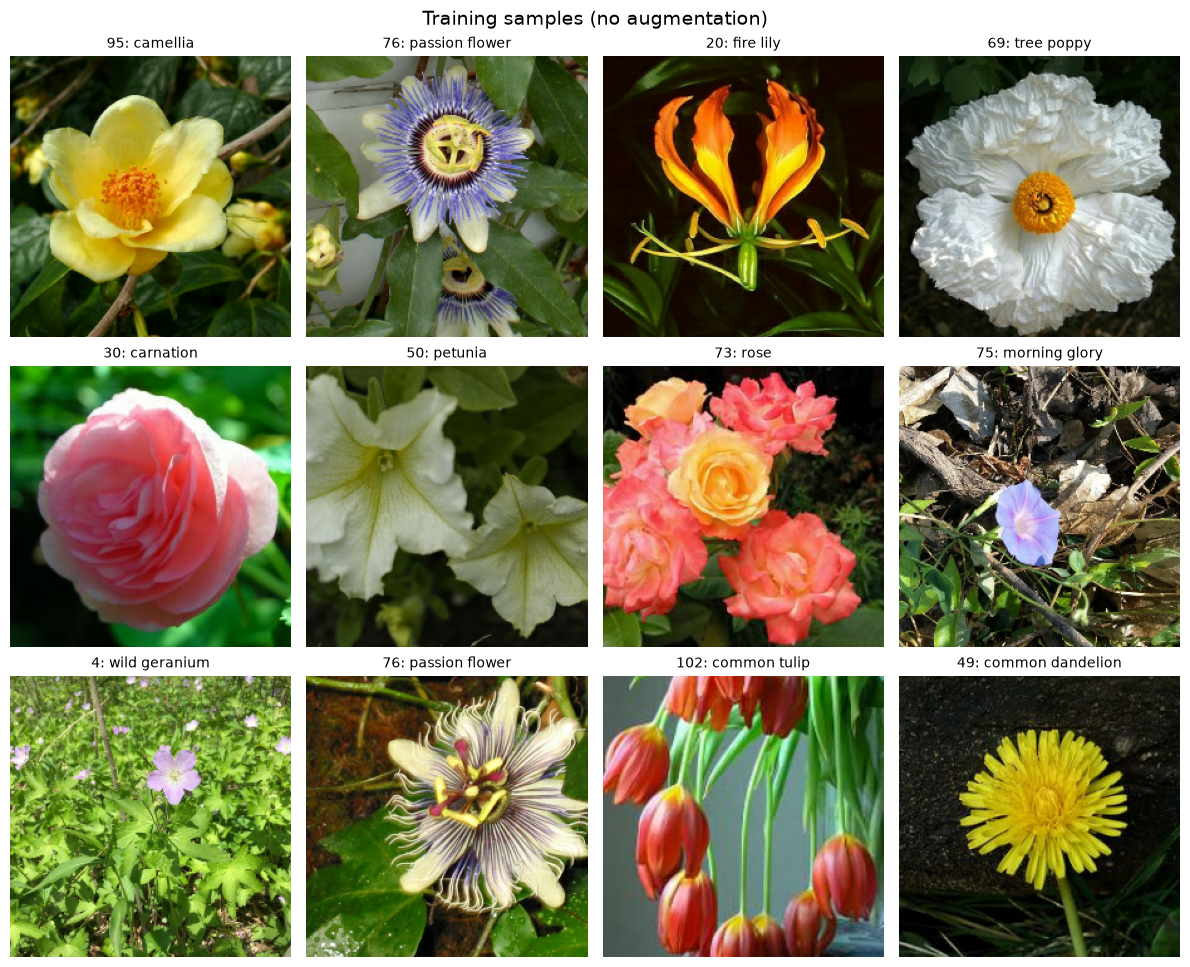

In [12]:
def show_images(images, titles, n_cols=4, suptitle=None):
    n_rows = int(np.ceil(len(images) / n_cols))
    plt.figure(figsize=(n_cols * 3, n_rows * 3.3))
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(n_rows, n_cols, i + 1)
        plt.imshow(img)
        plt.title(title, fontsize=10)
        plt.axis("off")
    if suptitle:
        plt.suptitle(suptitle, fontsize=14)
    plt.tight_layout()
    plt.show()

samples = list(load_dataset(TRAINING_FILENAMES).shuffle(500).take(12))
images = [img.numpy() for img, _ in samples]
titles = [f"{int(lbl)}: {CLASSES[int(lbl)]}" for _, lbl in samples]
show_images(images, titles, suptitle="Training samples (no augmentation)")

### Augmentation preview

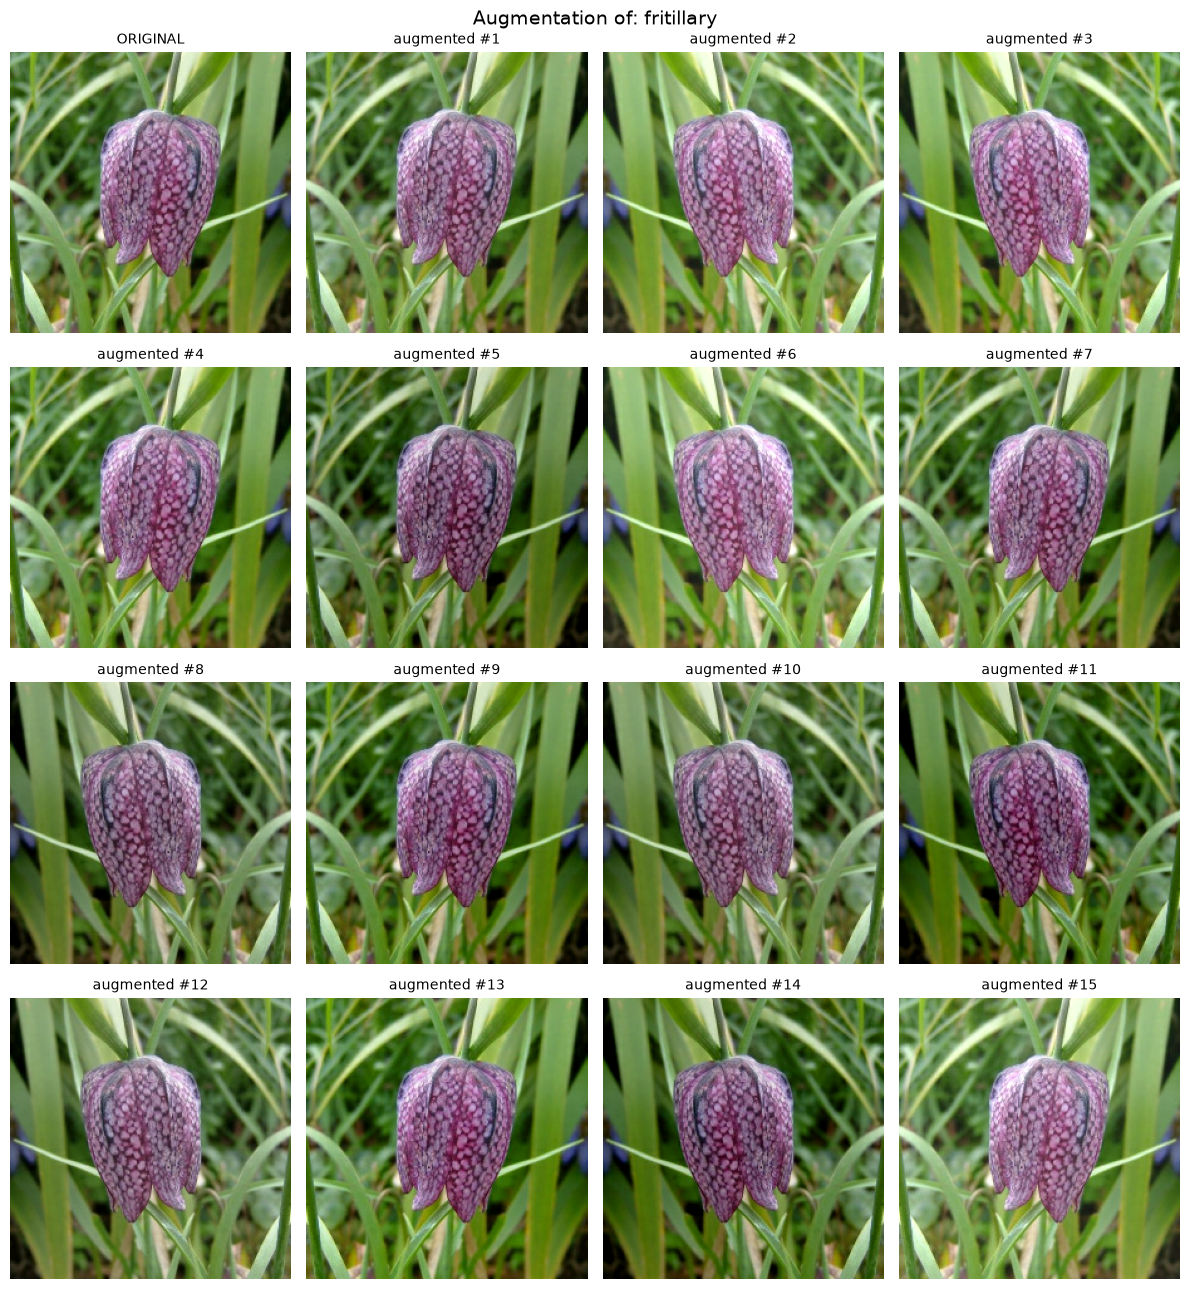

In [13]:
image, label = next(iter(load_dataset(TRAINING_FILENAMES)))

variants = [image.numpy()] + [data_augment(image, label)[0].numpy() for _ in range(15)]
titles   = ["ORIGINAL"] + [f"augmented #{i}" for i in range(1, 16)]
show_images(variants, titles, suptitle=f"Augmentation of: {CLASSES[int(label)]}")

### Class distribution
- ข้อมูลไม่สมดุลมาก → ใช้ Macro F1 วัดผล (ทุก class มีน้ำหนักเท่ากัน) จึงต้องระวัง class ที่มีรูปน้อย

รวม: 12753

มากสุด 3 ชนิด:
   67 iris                      782 รูป
  103 wild rose                 743 รูป
    4 wild geranium             703 รูป
น้อยสุด 3 ชนิด:
   34 alpine sea holly          18 รูป
   44 bolero deep blue          18 รูป
    6 moon orchid               18 รูป

ต่างกัน 43 เท่า


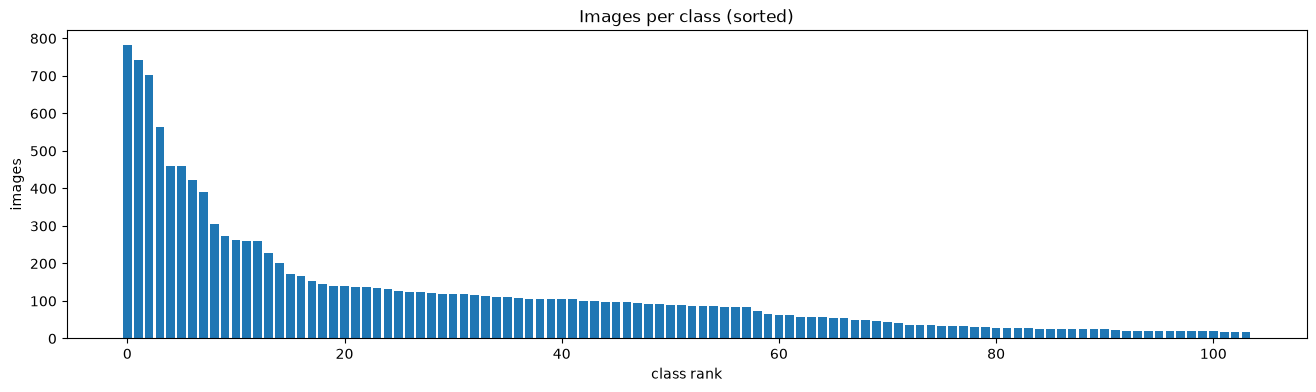

In [14]:
def read_label_only(example):
    fmt = {"class": tf.io.FixedLenFeature([], tf.int64)}
    return tf.io.parse_single_example(example, fmt)["class"]

def count_labels(filenames):
    ds = (tf.data.TFRecordDataset(filenames, num_parallel_reads=AUTO)
            .map(read_label_only, num_parallel_calls=AUTO)
            .batch(4096))
    labels = np.concatenate([b.numpy() for b in ds])
    return np.bincount(labels, minlength=NUM_CLASSES)

train_counts = count_labels(TRAINING_FILENAMES)
print("รวม:", train_counts.sum())

order = np.argsort(train_counts)[::-1]
print("\nมากสุด 3 ชนิด:")
for c in order[:3]:  print(f"  {c:3d} {CLASSES[c]:25s} {train_counts[c]} รูป")
print("น้อยสุด 3 ชนิด:")
for c in order[-3:]: print(f"  {c:3d} {CLASSES[c]:25s} {train_counts[c]} รูป")
print(f"\nต่างกัน {train_counts.max() / train_counts.min():.0f} เท่า")

plt.figure(figsize=(16, 4))
plt.bar(range(NUM_CLASSES), train_counts[order])
plt.title("Images per class (sorted)")
plt.xlabel("class rank"); plt.ylabel("images")
plt.show()

## Step 5: Check Device and Batch Size
- Mac M1: `REPLICAS = 1` → batch 16 · ถ้า GPU ว่างพอ ลองเพิ่มเป็น 32–64 ตอน train
- Kaggle TPU 8 คอร์: `BATCH_SIZE = 16 × 8 = 128`

In [15]:
print("strategy        :", type(strategy).__name__)
print("devices         :", [d.name for d in tf.config.list_logical_devices() if d.device_type != "CPU"] or "CPU only")
print("REPLICAS        :", REPLICAS)
print("BATCH_SIZE      :", BATCH_SIZE)
print("STEPS_PER_EPOCH :", STEPS_PER_EPOCH)

strategy        : _DefaultDistributionStrategy
devices         : ['/device:GPU:0']
REPLICAS        : 1
BATCH_SIZE      : 16
STEPS_PER_EPOCH : 797


## Step 6: Add Warm-up and Exponential Decay LR Schedule
- Learning Rate เริ่มต้นจาก 1e-5
- ปรับ LR MAX ตามขนาดของ batch ยิ่ง Batch ใหญ่ขึ้น LR ก็จะใหญ่ขึ้น (ทิศทางเชื่อถือได้มากขึ้น และก้าวได้ยาวขึ้นอย่างมั่นใจขึ้น) -> จำนวนก้าวต่อ Epoch ลดลง
    | Batch Size | Multiplier | LR_MAX |
    |:-----------|:-----------|:-------|
    | 16 (MacBook M1 Pro 2020) | 16/16 = 1 | 5e-5 |
    | 64 | 64/16 = 4 | 2e-4 |
    | 128 (TPU) | 128/16 = 8 | 4e-4 |
- Epoch 1-6 เป็นเส้นตรงขึ้น (Warm-up)
- Epoch 6 ได้จุดสูงสุด ซึ่งโมเดลจะเรียนรู้ได้เร็วที่สุด ค่า Loss ควรลดลงมากที่สุด
- Epoch 7-12 โค้งลง (decay) เพราะแต่ละ epoch ลดลงเป็นสัดส่วน (ช่วงแรกลดเยอะ ช่วงหลังน้อย) และปรับ Weights ละเอียดขึ้นเรื่อยๆ

BATCH_SIZE = 16 → LR_MAX = 5.00e-05

epoch  1: 1.00e-05
epoch  2: 1.80e-05
epoch  3: 2.60e-05
epoch  4: 3.40e-05
epoch  5: 4.20e-05
epoch  6: 5.00e-05
epoch  7: 4.20e-05
epoch  8: 3.56e-05
epoch  9: 3.05e-05
epoch 10: 2.64e-05
epoch 11: 2.31e-05
epoch 12: 2.05e-05


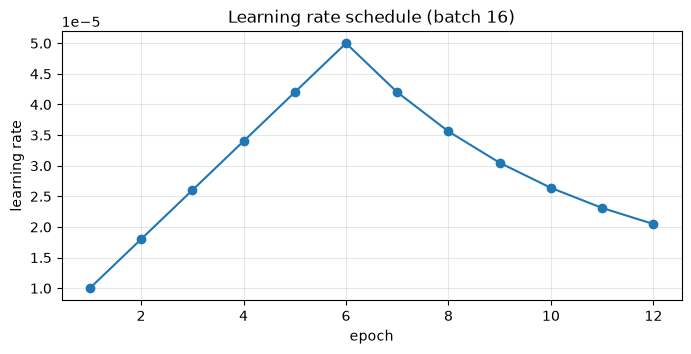

In [16]:
LR_START = 1e-5
LR_MAX   = 5e-5 * (BATCH_SIZE / 16)   # ปรับตาม batch size: batch ใหญ่ขึ้น k เท่า → LR สูงสุดเพิ่ม k เท่า
LR_MIN   = 1e-5
LR_RAMPUP_EPOCHS  = 5
LR_SUSTAIN_EPOCHS = 0
LR_DECAY = 0.8

def lrfn(epoch):
    """epoch เริ่มนับจาก 0 (Keras ส่งมาแบบนี้)"""
    if epoch < LR_RAMPUP_EPOCHS:                                   # ช่วง 1: ไต่ขึ้นเป็นเส้นตรง
        return LR_START + (LR_MAX - LR_START) * epoch / LR_RAMPUP_EPOCHS
    if epoch < LR_RAMPUP_EPOCHS + LR_SUSTAIN_EPOCHS:               # ช่วง 2: คงที่ที่ค่าสูงสุด
        return LR_MAX
    decay_epochs = epoch - LR_RAMPUP_EPOCHS - LR_SUSTAIN_EPOCHS    # ช่วง 3: ลดลงแบบ exponential
    return (LR_MAX - LR_MIN) * LR_DECAY ** decay_epochs + LR_MIN

lr_callback = tf.keras.callbacks.LearningRateScheduler(lrfn, verbose=True)

lrs = [lrfn(e) for e in range(EPOCHS)]
print(f"BATCH_SIZE = {BATCH_SIZE} → LR_MAX = {LR_MAX:.2e}\n")
for e, lr in enumerate(lrs):
    print(f"epoch {e + 1:2d}: {lr:.2e}")

plt.figure(figsize=(8, 3.5))
plt.plot(range(1, EPOCHS + 1), lrs, marker="o")
plt.title(f"Learning rate schedule (batch {BATCH_SIZE})")
plt.xlabel("epoch"); plt.ylabel("learning rate")
plt.grid(alpha=0.3)
plt.show()

## Step 7: Build Transfer-learning Model With Selectable Backbone

In [17]:
import platform

IS_MAC = platform.system() == "Darwin"

# ชื่อ → (ฟังก์ชันสร้าง backbone, ฟังก์ชันสร้าง layer ที่แปลง input 0–1 ให้ตรงกับที่ backbone เคยเห็นตอนเทรน)
BACKBONES = {
    "DenseNet201": (
        tf.keras.applications.DenseNet201,
        lambda: tf.keras.layers.Normalization(mean=[0.485, 0.456, 0.406],
                                              variance=[0.229**2, 0.224**2, 0.225**2]),
    ),
    "EfficientNetB0": (
        tf.keras.applications.EfficientNetB0,
        lambda: tf.keras.layers.Rescaling(255.0),              # 0–1 → 0–255 (EfficientNet normalize เองข้างใน)
    ),
    "MobileNetV2": (
        tf.keras.applications.MobileNetV2,
        lambda: tf.keras.layers.Rescaling(2.0, offset=-1.0),   # 0–1 → -1–1
    ),
}

def build_model(name):
    make_backbone, make_preprocess = BACKBONES[name]
    with strategy.scope():
        base = make_backbone(weights="imagenet", include_top=False, input_shape=[*IMAGE_SIZE, 3])
        base.trainable = True

        model = tf.keras.Sequential([
            tf.keras.Input(shape=[*IMAGE_SIZE, 3]),
            make_preprocess(),
            base,
            tf.keras.layers.GlobalAveragePooling2D(),
            tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
        ], name=name)

        model.compile(
            optimizer=tf.keras.optimizers.Adam(),
            loss="sparse_categorical_crossentropy",
            metrics=["sparse_categorical_accuracy"],
            steps_per_execution=16 if ON_TPU else 1,
            jit_compile=False if IS_MAC else "auto",
        )
    return model

In [18]:
import time

def seconds_per_step(name, n_steps=20):
    t0 = time.time()
    print("  ① สร้างโมเดล (ครั้งแรกจะดาวน์โหลด weights) ...", end=" ", flush=True)
    tf.keras.backend.clear_session()
    model = build_model(name)
    ds = get_training_dataset()
    print(f"{time.time() - t0:.0f}s")

    t0 = time.time()
    print("  ② warm-up 3 steps (ไม่นับเวลา) ...", end=" ", flush=True)
    model.fit(ds, steps_per_epoch=3, epochs=1, verbose=0)
    print(f"{time.time() - t0:.0f}s")

    print(f"  ③ จับเวลา {n_steps} steps:")
    t0 = time.time()
    model.fit(ds, steps_per_epoch=n_steps, epochs=1, verbose=1)
    return (time.time() - t0) / n_steps


RUN_BENCHMARK = not ON_TPU   # บน TPU ข้าม เพื่อไม่ให้เปลืองโควตา

if RUN_BENCHMARK:
    print(f"batch {BATCH_SIZE}, {STEPS_PER_EPOCH} steps/epoch, {EPOCHS} epochs\n")

    results = {}
    for i, name in enumerate(BACKBONES, start=1):
        print(f"[{i}/{len(BACKBONES)}] {name}")
        results[name] = seconds_per_step(name)
        print()

    print("=" * 72)
    for name, sec in results.items():
        epoch_min = sec * STEPS_PER_EPOCH / 60
        print(f"{name:15s} {sec:.3f} s/step → {epoch_min:5.1f} นาที/epoch → รวม {epoch_min * EPOCHS / 60:4.1f} ชม.")
else:
    print("⏭️ ข้ามการจับเวลา (รันบน TPU)")

batch 16, 797 steps/epoch, 12 epochs

[1/3] DenseNet201
  ① สร้างโมเดล (ครั้งแรกจะดาวน์โหลด weights) ... 5s
  ② warm-up 3 steps (ไม่นับเวลา) ... 

/Volumes/onetedrive/00new_appr/flower-classification-on-tpu/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


429s
  ③ จับเวลา 20 steps:
20/20 ━━━━━━━━━━━━━━━━━━━━ 441s 20s/step - loss: 4.1081 - sparse_categorical_accuracy: 0.1969

[2/3] EfficientNetB0
  ① สร้างโมเดล (ครั้งแรกจะดาวน์โหลด weights) ... 124s
  ② warm-up 3 steps (ไม่นับเวลา) ... 83s
  ③ จับเวลา 20 steps:
20/20 ━━━━━━━━━━━━━━━━━━━━ 64s 3s/step - loss: 3.9319 - sparse_categorical_accuracy: 0.1875

[3/3] MobileNetV2
  ① สร้างโมเดล (ครั้งแรกจะดาวน์โหลด weights) ... 9s
  ② warm-up 3 steps (ไม่นับเวลา) ... 56s
  ③ จับเวลา 20 steps:
20/20 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step - loss: 3.8238 - sparse_categorical_accuracy: 0.2313

DenseNet201     22.064 s/step → 293.1 นาที/epoch → รวม 58.6 ชม.
EfficientNetB0  3.209 s/step →  42.6 นาที/epoch → รวม  8.5 ชม.
MobileNetV2     2.086 s/step →  27.7 นาที/epoch → รวม  5.5 ชม.


In [19]:
MODEL_NAME = "DenseNet201" if ON_TPU else "MobileNetV2"   # M1 ใช้ตัวเล็กสุด แค่ทดสอบว่าโค้ดรันได้

tf.keras.backend.clear_session()
model = build_model(MODEL_NAME)
model.summary()

# ตรวจ 1: output เป็นความน่าจะเป็นของ 104 ชนิด
batch_images, batch_labels = next(iter(get_training_dataset()))
probs = model.predict(batch_images, verbose=0)
print("\noutput shape :", probs.shape)
print("ผลรวมแต่ละแถว:", np.round(probs.sum(axis=1)[:4], 4))

# ตรวจ 2: ก่อนเทรน โมเดลควรทายได้แย่พอ ๆ กับการเดาสุ่ม
loss, acc = model.evaluate(get_validation_dataset().take(10), verbose=0)
print(f"\nloss     : {loss:.2f}   (เดาสุ่มได้ ≈ {np.log(NUM_CLASSES):.2f})")
print(f"accuracy : {acc:.3f}  (เดาสุ่มได้ ≈ {1 / NUM_CLASSES:.3f})")

Model: "MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 104)            │       133,224 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,391,208 (9.12 MB)

 Trainable params: 2,357,096 (8.99 MB)

 Non-trainable params: 34,112 (133.25 KB)


output shape : (16, 104)
ผลรวมแต่ละแถว: [1. 1. 1. 1.]

loss     : 4.98   (เดาสุ่มได้ ≈ 4.64)
accuracy : 0.044  (เดาสุ่มได้ ≈ 0.010)


2026-10-12 21:11:41.341991: W tensorflow/core/kernels/data/cache_dataset_ops.cc:914] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
/Volumes/onetedrive/00new_appr/flower-classification-on-tpu/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


## Step 8: Train Model and Plot Loss / Accuracy History
- รันสั้นๆเพื่อเช็คโค้ดบน M1
- รันจริงบน Kaggle TPU เพื่อให้ได้โมเดลไว้ submit